Predicting Stock Market Prices	Perform rigorous stationarity testing on the TSLA Close price time series using Augmented Dickey-Fuller (ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests to validate the suitability of the data for time series modeling, and interpret the results fo

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
warnings.filterwarnings('ignore')

In [6]:
# Load dataset and sort chronologically
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Create candidate stationary transformations
df['Close_Diff1'] = df['Close'].diff()
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))

print(f"Loaded {len(df)} trading days ({df['Date'].min().date()} to {df['Date'].max().date()})")
df[['Date', 'Close', 'Close_Diff1', 'Log_Return']].head()

Loaded 100 trading days (2025-01-02 to 2025-05-14)


,Date,Close,Close_Diff1,Log_Return
0,2025-01-02,381.88,NaN,NaN
1,2025-01-03,376.36,-5.52,-0.014560
2,2025-01-06,380.68,4.32,0.011413
3,2025-01-07,386.06,5.38,0.014034
4,2025-01-08,375.53,-10.53,-0.027654


In [7]:
def evaluate_stationarity(series, series_name, kpss_regression='c', alpha=0.05):
    """
    Runs both ADF (H0: Non-Stationary / Unit Root) and KPSS (H0: Stationary)
    and synthesizes the joint statistical verdict.
    """
    clean_series = series.dropna()
    
    # 1. Augmented Dickey-Fuller (ADF) Test
    adf_stat, adf_pval, adf_lags, nobs, adf_crit, _ = adfuller(clean_series, autolag='AIC')
    adf_stationary = adf_pval < alpha
    
    # 2. Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test
    kpss_stat, kpss_pval, kpss_lags, kpss_crit = kpss(clean_series, regression=kpss_regression, nlags='auto')
    kpss_stationary = kpss_pval >= alpha
    
    # Joint Decision Matrix
    if adf_stationary and kpss_stationary:
        verdict = "Strictly Stationary (I(0))"
    elif not adf_stationary and not kpss_stationary:
        verdict = "Non-Stationary (Unit Root I(1))"
    elif adf_stationary and not kpss_stationary:
        verdict = "Difference-Stationary / Trend-Driven"
    else:
        verdict = "Trend-Stationary (Needs Detrending)"
        
    return {
        'Series': series_name,
        'KPSS_Type': f"'{kpss_regression}'",
        'ADF_Stat': round(adf_stat, 4),
        'ADF_pVal': round(adf_pval, 4),
        'ADF_5%_Crit': round(adf_crit['5%'], 4),
        'KPSS_Stat': round(kpss_stat, 4),
        'KPSS_pVal': round(kpss_pval, 4),
        'KPSS_5%_Crit': round(kpss_crit['5%'], 4),
        'Joint_Verdict': verdict
    }

# Evaluate Raw Close (Level & Trend), 1st-Order Differenced Close, and Daily Log Returns
results = [
    evaluate_stationarity(df['Close'], 'Raw Close Price (Level)', kpss_regression='c'),
    evaluate_stationarity(df['Close'], 'Raw Close Price (Trend)', kpss_regression='ct'),
    evaluate_stationarity(df['Close_Diff1'], '1st Difference Close (d=1)', kpss_regression='c'),
    evaluate_stationarity(df['Log_Return'], 'Daily Log Return', kpss_regression='c')
]

results_df = pd.DataFrame(results)
print("--- Joint ADF & KPSS Stationarity Test Results (alpha = 0.05) ---")
print(results_df.to_string(index=False))


--- Joint ADF & KPSS Stationarity Test Results (alpha = 0.05) ---
                    Series KPSS_Type  ADF_Stat  ADF_pVal  ADF_5%_Crit  KPSS_Stat  KPSS_pVal  KPSS_5%_Crit                   Joint_Verdict
   Raw Close Price (Level)       'c'   -1.5451    0.5111      -2.8912     1.2578       0.01         0.463 Non-Stationary (Unit Root I(1))
   Raw Close Price (Trend)      'ct'   -1.5451    0.5111      -2.8912     0.3450       0.01         0.146 Non-Stationary (Unit Root I(1))
1st Difference Close (d=1)       'c'   -9.4303    0.0000      -2.8915     0.1297       0.10         0.463      Strictly Stationary (I(0))
          Daily Log Return       'c'   -9.4514    0.0000      -2.8915     0.1296       0.10         0.463      Strictly Stationary (I(0))


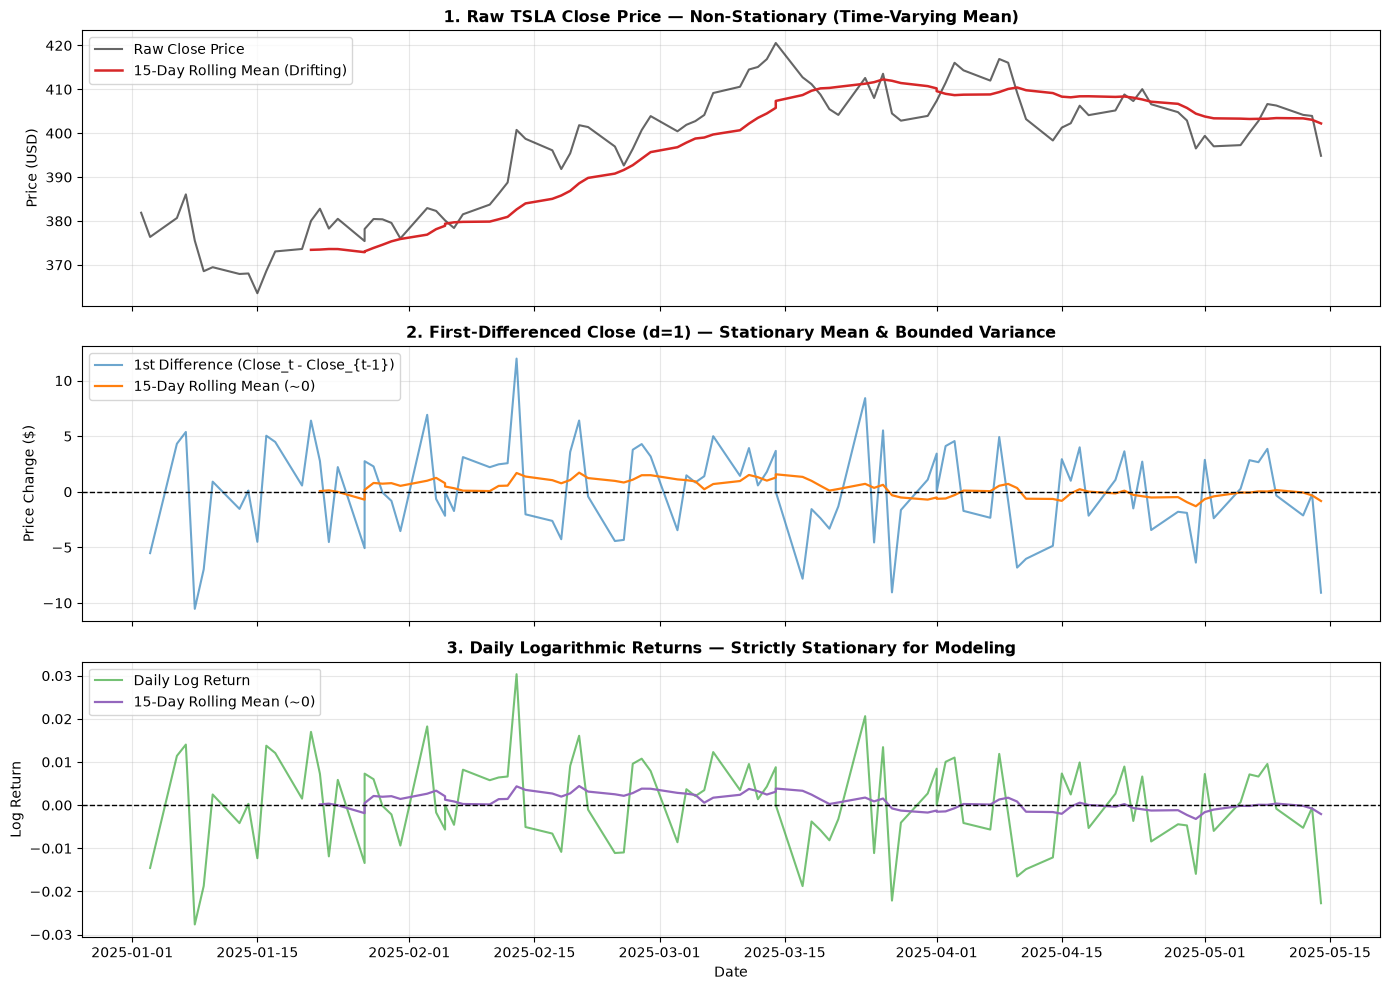

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
window = 15

# Panel 1: Raw Close Price (Non-Stationary Drift)
axes[0].plot(df['Date'], df['Close'], color='black', alpha=0.6, label='Raw Close Price')
axes[0].plot(df['Date'], df['Close'].rolling(window).mean(), color='#d62728', linewidth=1.8, label=f'{window}-Day Rolling Mean (Drifting)')
axes[0].set_title('1. Raw TSLA Close Price — Non-Stationary (Time-Varying Mean)', fontsize=11.5, fontweight='bold')
axes[0].set_ylabel('Price (USD)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# Panel 2: First-Order Differenced Close (d=1 Stationary)
axes[1].plot(df['Date'], df['Close_Diff1'], color='#1f77b4', alpha=0.65, label='1st Difference (Close_t - Close_{t-1})')
axes[1].plot(df['Date'], df['Close_Diff1'].rolling(window).mean(), color='#ff7f0e', linewidth=1.6, label=f'{window}-Day Rolling Mean (~0)')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('2. First-Differenced Close (d=1) — Stationary Mean & Bounded Variance', fontsize=11.5, fontweight='bold')
axes[1].set_ylabel('Price Change ($)')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

# Panel 3: Daily Log Returns (Stationary)
axes[2].plot(df['Date'], df['Log_Return'], color='#2ca02c', alpha=0.65, label='Daily Log Return')
axes[2].plot(df['Date'], df['Log_Return'].rolling(window).mean(), color='#9467bd', linewidth=1.6, label=f'{window}-Day Rolling Mean (~0)')
axes[2].axhline(0, color='black', linestyle='--', linewidth=1)
axes[2].set_title('3. Daily Logarithmic Returns — Strictly Stationary for Modeling', fontsize=11.5, fontweight='bold')
axes[2].set_ylabel('Log Return')
axes[2].set_xlabel('Date')
axes[2].legend(loc='upper left')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()